# 2. BTC MONDAY EFFECT - IN-SAMPLE PARAMETER STABILITY & PLATEAU CHECK

This notebook runs the in-sample sensitivity analysis of the **BTC Monday Effect (v3)** rules on hourly BTC/USDT bars (UTC), following the same flow as notebook 02 of the RSI2 edge.

### STRICT METHODOLOGICAL CONSTRAINT
> **IN-SAMPLE DATA ONLY**: everything before `split.oos_start` (2024-01-08). Out-of-sample data is not touched here; it belongs to notebook 03.

### OBJECTIVES
1. **Plateau vs. Cliff Validation**: the configured point (`atr_pctl`, `atr_len`) must sit on a stable region of the grid `grid.atr_pctl_values x grid.atr_len_values`, not on an isolated peak.
2. **Anti-Cliff Check**: one step away in any direction must not drop the Profit Factor by more than the gate limit.

### EDGE-SPECIFIC CHECKS (they matter more than the generic ones)
3. **Dose-response**: more volatility filter (higher percentile) should mean a higher net mean per Monday, not a random profile.
4. **Entry-hour robustness**: the rule should not depend on the exact 00:00 UTC entry.
5. **Filter ablation by era**: what each filter (volatility, calendar) contributes, in the retail and institutional eras that are inside the in-sample block.

### STRATEGY PARAMETERS

In [1]:
VARIANT = "base_btcusdt"  # only base variants here; see variants/*.yaml

## 1. IMPORTS AND CONFIG

In [2]:
import os
import sys
import json
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---- Paths ----
def find_upwards(name, start=None, must_be_dir=True):
    """Walk up from start (cwd by default) and return the first folder that contains `name`."""
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"Could not find '{name}' walking up from {here}")

EDGE_DIR   = find_upwards('variants')                  # edge folder (notebooks, engine and variants/ live together)
utils_path = str(find_upwards('utils') / 'utils')      # research_development/utils
for p in (utils_path, str(EDGE_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import compute_metrics
from metrics import sharpe_ratio, max_drawdown
from robustness import grid_search, plateau_check, plot_grid, profit_factor
from validation_gate import DEFAULTS as GATE
import monday_effect_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)   # resets ENGINE_DEFAULTS: nothing leaks between variants

variant_config.EDGE_DIR = EDGE_DIR
assert (variant_config.EDGE_DIR / "variants").is_dir(), f"Doesn't exist {variant_config.EDGE_DIR / 'variants'}"

# ---- Variant config: single source of truth ----
cfg        = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
P          = cfg["params"]
VOL_MODE, ATR_PCTL, ATR_LEN = P["vol_mode"], float(P["atr_pctl"]), int(P["atr_len"])
SKIP1, ENTRY_HOUR, HOLD, COST_BPS = P["skip_first_monday"], P["entry_hour"], P["hold_bars"], P["cost_bps_per_side"]
PCTLS      = [float(x) for x in cfg["grid"]["atr_pctl_values"]]
ATR_LENS   = [int(x) for x in cfg["grid"]["atr_len_values"]]
CHOSEN     = (ATR_PCTL, ATR_LEN)

# Rules that never change in this notebook (atr_pctl / atr_len are swept)
RULES_KW = dict(vol_mode=VOL_MODE, skip_first_monday=SKIP1, entry_hour=ENTRY_HOUR,
                hold_bars=HOLD, cost_bps_per_side=COST_BPS)

# ---- Style and small helpers (same palette as notebook 01) ----
BG, PANEL, GRIDC, TXT, SUB, GREEN, RED, ORANGE = "#15171c", "#1b1e26", "#2a2d37", "#e8e9ec", "#9aa0ab", "#34d399", "#f0555a", "#f5a524"
def dark_ax(ax):
    ax.set_facecolor(PANEL)
    ax.grid(color=GRIDC, alpha=0.8)
    ax.tick_params(colors=SUB)
    for s in ax.spines.values():
        s.set_visible(False)

ERAS = {"Retail (2017-19)": (2017, 2019), "Institutional (2020-23)": (2020, 2023), "ETF (2024+)": (2024, 2100)}
def era_of(y):
    return next(k for k, (a, b) in ERAS.items() if a <= y <= b)

def tstat(x):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    return float(x.mean() / (x.std(ddof=1) / np.sqrt(len(x)))) if len(x) > 2 and x.std(ddof=1) > 0 else np.nan

def summarize(t):
    """PF / mean net % / t-stat / win rate of a trades frame (100% capital, net of costs)."""
    if len(t) == 0:
        return dict(n=0, pf=np.nan, mean=np.nan, t=np.nan, win=np.nan)
    return dict(n=len(t), pf=profit_factor(t["pnl"]), mean=float(t["pnl"].mean()),
                t=tstat(t["pnl"]), win=float((t["pnl"] > 0).mean() * 100))

print("Imports complete.")
print(f"Loaded monday_effect_engine from: {eng.__file__}")
print(f"Edge dir: {EDGE_DIR}")
print(f"Variant: {cfg['id']} | {TICKER} | candidate P{ATR_PCTL:g}, ATR({ATR_LEN}) | skip first Monday={SKIP1} | {COST_BPS:g} bps/side")
print(f"Grid: {len(PCTLS)} percentiles x {len(ATR_LENS)} ATR lengths = {len(PCTLS) * len(ATR_LENS)} cells")
print(f"Gate criteria (validation_gate.DEFAULTS): PF >= {GATE['plateau_pf_min']}, N >= {GATE['plateau_n_min']}, max drop {GATE['plateau_max_drop']}%")
print(f"Run folder: {RUN_DIR}")

Imports complete.
Loaded monday_effect_engine from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/Monday_Effect/monday_effect_engine.py
Edge dir: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/Monday_Effect
Variant: MONDAY.btcusdt.base | btcusdt | candidate P30, ATR(48) | skip first Monday=True | 14 bps/side
Grid: 7 percentiles x 6 ATR lengths = 42 cells
Gate criteria (validation_gate.DEFAULTS): PF >= 1.3, N >= 30, max drop 30%
Run folder: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/Monday_Effect/runs/base_btcusdt


## 2. IN-SAMPLE DATA SETUP

`prepare()` is called once per ATR length on the full history (so the 1-year percentile is warm), then every grid cell is cut to the **same** window: from the first Monday where *all* ATR lengths have a valid percentile, up to the day before `oos_start`.

In [3]:
df_raw = eng.load_data(TICKER, start=DATA_START)

preps = {L: eng.prepare(df_raw, atr_len=L, entry_hour=ENTRY_HOUR) for L in ATR_LENS}
common_start = max(d.index[d["atr_rank"].notna()][0] for d in preps.values())

is_dfs = {}
for L, d in preps.items():
    d = d[d.index >= common_start]
    is_dfs[L] = d[d.index < OOS_START].copy()

assert len({(d.index[0], d.index[-1], len(d)) for d in is_dfs.values()}) == 1, "All ATR lengths must use the same date window."
assert len(is_dfs[ATR_LEN]) > 0, "Check split.oos_start against the history."
d0 = is_dfs[ATR_LEN]

print("=" * 70)
print("IN-SAMPLE WINDOW (ONE WINDOW FOR EVERY GRID CELL)")
print("=" * 70)
print(f"Strict In-Sample Range: {d0.index.min():%Y-%m-%d} to {d0.index.max():%Y-%m-%d}")
print(f"Total In-Sample Bars: {len(d0):,}")
print(f"Mondays with a valid signal bar and percentile: {int(d0['atr_rank'].notna().sum())}")
print(f"OOS block (not used here) starts: {OOS_START:%Y-%m-%d}")

IN-SAMPLE WINDOW (ONE WINDOW FOR EVERY GRID CELL)
Strict In-Sample Range: 2018-02-26 to 2024-01-07
Total In-Sample Bars: 51,320
Mondays with a valid signal bar and percentile: 306
OOS block (not used here) starts: 2024-01-08


## 3. 2D PARAMETER GRID (ATR PERCENTILE x ATR LENGTH)

Each cell runs the frozen rules with only `atr_pctl` and `atr_len` changed. PF is the plateau metric (as in RSI2); mean net return and t-stat are added because PF alone can be carried by a few Mondays in a strategy that trades ~20 times a year.

IN-SAMPLE PROFIT FACTOR GRID (rows = ATR percentile, columns = ATR length)


,12,24,48,72,96,168
0.0,0.966,0.966,0.966,0.966,0.966,0.966
10.0,0.950,0.957,0.958,0.922,0.901,0.929
20.0,1.075,1.104,1.195,1.136,0.981,0.902
30.0,1.279,1.381,1.475,1.238,1.166,1.003
40.0,1.287,1.310,1.527,1.477,1.151,1.223
50.0,1.385,1.322,1.395,1.452,1.423,1.268
60.0,1.304,1.558,1.559,1.409,1.651,1.210



IN-SAMPLE TRADE COUNT GRID (N)


,12,24,48,72,96,168
0.0,232,232,232,232,232,232
10.0,189,165,156,166,178,184
20.0,157,137,119,139,150,153
30.0,126,101,88,107,117,132
40.0,102,74,76,84,93,106
50.0,80,66,62,72,76,83
60.0,65,51,50,55,61,73



MEAN NET RETURN PER MONDAY, % (100% capital)


,12,24,48,72,96,168
0.0,-0.053,-0.053,-0.053,-0.053,-0.053,-0.053
10.0,-0.084,-0.075,-0.074,-0.139,-0.173,-0.120
20.0,0.124,0.176,0.326,0.217,-0.033,-0.182
30.0,0.429,0.628,0.779,0.398,0.294,0.005
40.0,0.464,0.586,0.902,0.787,0.284,0.382
50.0,0.648,0.640,0.738,0.818,0.751,0.468
60.0,0.578,1.069,1.086,0.806,1.073,0.395



t-STAT OF THE MEAN


,12,24,48,72,96,168
0.0,-0.19,-0.19,-0.19,-0.19,-0.19,-0.19
10.0,-0.25,-0.20,-0.19,-0.37,-0.50,-0.35
20.0,0.32,0.42,0.70,0.53,-0.08,-0.46
30.0,0.97,1.16,1.33,0.78,0.60,0.01
40.0,0.89,0.85,1.36,1.30,0.49,0.75
50.0,1.03,0.84,0.96,1.18,1.13,0.78
60.0,0.77,1.18,1.17,0.94,1.46,0.59


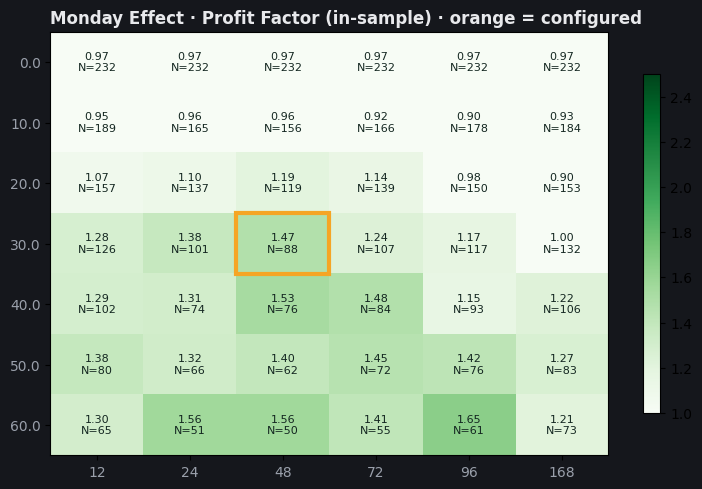

In [4]:
TR = {}   # (pctl, atr_len) -> in-sample trades, reused by every later cell

def evaluate(pctl, L):
    t = eng.run_monday_backtest(is_dfs[L], atr_pctl=pctl, atr_len=L, **RULES_KW)
    TR[(pctl, L)] = t
    return (profit_factor(t["pnl"]) if len(t) else 0.0, len(t))

pf_grid, n_grid = grid_search(evaluate, PCTLS, ATR_LENS)
mean_grid = pd.DataFrame({L: {p: summarize(TR[(p, L)])["mean"] for p in PCTLS} for L in ATR_LENS})
t_grid    = pd.DataFrame({L: {p: summarize(TR[(p, L)])["t"] for p in PCTLS} for L in ATR_LENS})

print("=" * 70)
print("IN-SAMPLE PROFIT FACTOR GRID (rows = ATR percentile, columns = ATR length)")
print("=" * 70)
display(pf_grid.round(3))
print("\n" + "=" * 70)
print("IN-SAMPLE TRADE COUNT GRID (N)")
print("=" * 70)
display(n_grid.astype(int))
print("\n" + "=" * 70)
print("MEAN NET RETURN PER MONDAY, % (100% capital)")
print("=" * 70)
display(mean_grid.round(3))
print("\n" + "=" * 70)
print("t-STAT OF THE MEAN")
print("=" * 70)
display(t_grid.round(2))

plot_grid(pf_grid, n_grid, CHOSEN, title="Monday Effect · Profit Factor (in-sample) · orange = configured")

## 4. PLATEAU & ANTI-CLIFF CHECK

Official criterion = `robustness.plateau_check` with the thresholds of `validation_gate.DEFAULTS`. Note that the ATR-length axis is not evenly spaced (12, 24, 48, 72, 96, 168): "one step away" means the adjacent grid value.

In [5]:
pl = plateau_check(pf_grid, n_grid, CHOSEN, pf_min=GATE["plateau_pf_min"], n_min=GATE["plateau_n_min"],
                   max_drop_pct=GATE["plateau_max_drop"])

ia, ib = pf_grid.index.get_loc(ATR_PCTL), pf_grid.columns.get_loc(ATR_LEN)
sl = (slice(max(ia - 1, 0), ia + 2), slice(max(ib - 1, 0), ib + 2))
cells = pf_grid.stack()
rank = int((cells > pf_grid.loc[ATR_PCTL, ATR_LEN]).sum()) + 1

print("=" * 70)
print(f"3x3 NEIGHBORHOOD OF THE CONFIGURED POINT P{ATR_PCTL:g}, ATR({ATR_LEN})")
print("=" * 70)
print("Profit Factor:"); display(pf_grid.iloc[sl].round(3))
print("N trades:");      display(n_grid.iloc[sl].astype(int))
print(f"Center PF: {pl['center_pf']:.3f} | worst neighbor drop: {pl['worst_neighbor_drop_pct']:.1f}% (max {GATE['plateau_max_drop']}%)")
print(f"Plateau (all 9 cells PF >= {GATE['plateau_pf_min']} and N >= {GATE['plateau_n_min']}): {'YES' if pl['plateau'] else 'NO'}")
print(f"Anti-cliff: {'PASS' if pl['anticliff'] else 'FAIL'} | Gate (plateau AND anti-cliff): {'PASS' if pl['passed'] else 'FAIL'}")
print(f"Cells with PF >= {GATE['plateau_pf_min']}: {pl['pct_cells_pf_ok'] * 100:.0f}% of {len(cells)} | cells with mean net > 0: {int((mean_grid.stack() > 0).sum())} of {len(cells)}")
print(f"Configured point ranks #{rank} of {len(cells)} by PF | best cell: {pl['best_cell']} (PF {pl['best_pf']:.3f}) | configured on grid edge: {pl['edge_of_grid']}")

# ---- Secondary diagnostic (NOT the gate): same check inside the institutional era only ----
# The era split is part of the hypothesis (notebook 01, section 1.1), and the retail era (2017-19) is inside the IS block.
a, b = ERAS["Institutional (2020-23)"]
def era_trades(t):
    y = pd.to_datetime(t["entry_time"]).dt.year
    return t[(y >= a) & (y <= b)]
pf_i = pd.DataFrame({L: {p: (profit_factor(era_trades(TR[(p, L)])["pnl"]) if len(era_trades(TR[(p, L)])) else 0.0) for p in PCTLS} for L in ATR_LENS})
n_i  = pd.DataFrame({L: {p: float(len(era_trades(TR[(p, L)]))) for p in PCTLS} for L in ATR_LENS})
pl_i = plateau_check(pf_i, n_i, CHOSEN, pf_min=GATE["plateau_pf_min"], n_min=GATE["plateau_n_min"], max_drop_pct=GATE["plateau_max_drop"])
print("\n" + "-" * 70)
print(f"DIAGNOSTIC · institutional era only ({a}-{b}): center PF {pl_i['center_pf']:.3f} | plateau {'YES' if pl_i['plateau'] else 'NO'} | "
      f"worst drop {pl_i['worst_neighbor_drop_pct']:.1f}% | gate {'PASS' if pl_i['passed'] else 'FAIL'}")
display(pf_i.round(3))

3x3 NEIGHBORHOOD OF THE CONFIGURED POINT P30, ATR(48)
Profit Factor:


,24,48,72
20.0,1.104,1.195,1.136
30.0,1.381,1.475,1.238
40.0,1.310,1.527,1.477


N trades:


,24,48,72
20.0,137,119,139
30.0,101,88,107
40.0,74,76,84


Center PF: 1.475 | worst neighbor drop: 25.1% (max 30%)
Plateau (all 9 cells PF >= 1.3 and N >= 30): NO
Anti-cliff: PASS | Gate (plateau AND anti-cliff): FAIL
Cells with PF >= 1.3: 36% of 42 | cells with mean net > 0: 28 of 42
Configured point ranks #6 of 42 by PF | best cell: (np.float64(60.0), np.int64(96)) (PF 1.651) | configured on grid edge: False

----------------------------------------------------------------------
DIAGNOSTIC · institutional era only (2020-2023): center PF 1.284 | plateau NO | worst drop 21.4% | gate FAIL


,12,24,48,72,96,168
0.0,0.966,0.966,0.966,0.966,0.966,0.966
10.0,0.913,0.876,0.976,0.934,0.918,0.919
20.0,0.978,1.009,1.045,1.043,0.951,0.875
30.0,1.213,1.291,1.284,1.091,1.084,0.957
40.0,1.171,1.132,1.351,1.314,1.130,1.065
50.0,1.202,1.115,1.213,1.330,1.299,1.107
60.0,1.189,1.435,1.351,1.265,1.526,1.034


## 5. DOSE-RESPONSE: DOES MORE VOLATILITY FILTER MEAN MORE EDGE?

With `atr_len` fixed at the configured value, only the percentile changes. A healthy filter shows a roughly monotonic climb of the net mean per trade (at the cost of fewer trades). `P0` is the unfiltered Monday (still with the calendar filter).

DOSE-RESPONSE AT ATR(48) · in-sample · 100% capital, net of 14 bps/side


,Trades,PF,Mean net %,t-stat,Win %
atr_pctl,,,,,
0.0,232.0,0.966,-0.053,-0.186,43.966
10.0,156.0,0.958,-0.074,-0.189,43.590
20.0,119.0,1.195,0.326,0.696,48.739
30.0,88.0,1.475,0.779,1.326,48.864
40.0,76.0,1.527,0.902,1.359,50.000
50.0,62.0,1.395,0.738,0.960,50.000
60.0,50.0,1.559,1.086,1.171,52.000


Spearman (percentile vs mean net return): rho = +0.86 (p = 0.014, only 7 points: descriptive)


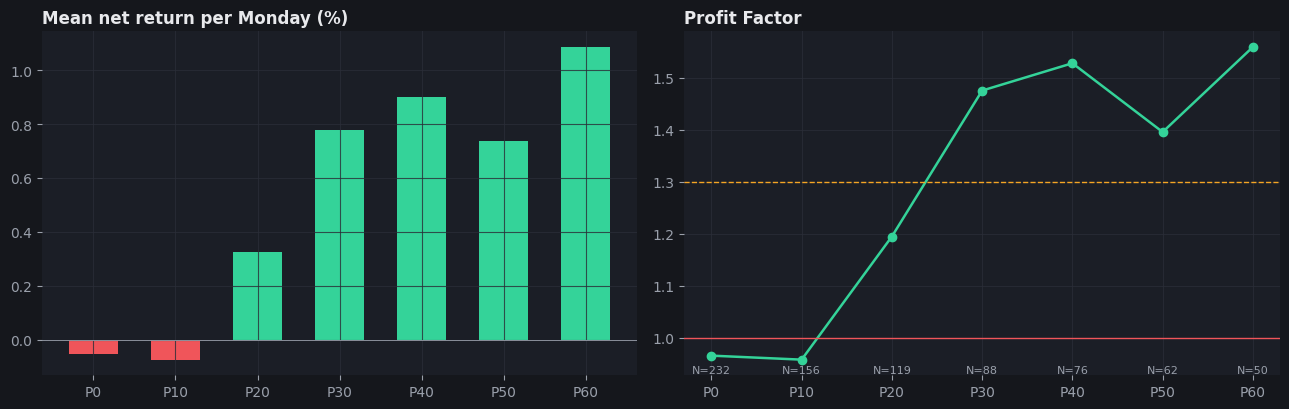

In [6]:
dose = pd.DataFrame({p: summarize(TR[(p, ATR_LEN)]) for p in PCTLS}).T
dose.index.name = "atr_pctl"
rho_d, p_d = stats.spearmanr(dose.index.to_numpy(float), dose["mean"].to_numpy(float))

print("=" * 70)
print(f"DOSE-RESPONSE AT ATR({ATR_LEN}) · in-sample · 100% capital, net of {COST_BPS:g} bps/side")
print("=" * 70)
display(dose.rename(columns={"n": "Trades", "pf": "PF", "mean": "Mean net %", "t": "t-stat", "win": "Win %"}).round(3))
print(f"Spearman (percentile vs mean net return): rho = {rho_d:+.2f} (p = {p_d:.3f}, only {len(dose)} points: descriptive)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), facecolor=BG)
dark_ax(ax1); dark_ax(ax2)
x = np.arange(len(dose))
ax1.bar(x, dose["mean"], color=[GREEN if v > 0 else RED for v in dose["mean"]], width=0.6)
ax1.axhline(0, color=SUB, lw=0.6)
ax1.set_xticks(x); ax1.set_xticklabels([f"P{p:g}" for p in dose.index], color=SUB)
ax1.set_title("Mean net return per Monday (%)", color=TXT, fontweight="bold", loc="left")
ax2.plot(x, dose["pf"].clip(upper=8), color=GREEN, lw=1.8, marker="o")
ax2.axhline(1.0, color=RED, lw=1.0); ax2.axhline(GATE["plateau_pf_min"], color=ORANGE, ls="--", lw=1.0)
ax2.set_xticks(x); ax2.set_xticklabels([f"P{p:g}" for p in dose.index], color=SUB)
ax2.set_title("Profit Factor", color=TXT, fontweight="bold", loc="left")
for i, n in enumerate(dose["n"]):
    ax2.text(i, ax2.get_ylim()[0], f"N={int(n)}", color=SUB, fontsize=8, ha="center", va="bottom")
plt.tight_layout(); plt.show()

## 6. ENTRY-HOUR ROBUSTNESS

The signal is the Sunday 23:00 close and the entry is Monday 00:00 UTC. Here the entry hour moves (the position is always held 24 bars), with the configured volatility and calendar filters, next to the naked Monday at the same hour. If the edge lived only at 00:00 it would be a data artefact.

In [7]:
HOURS = [0, 1, 2, 3, 4, 6, 8, 12]
rows = []
for h in HOURS:
    d = eng.prepare(df_raw, atr_len=ATR_LEN, entry_hour=h)
    start_h = max(d.index[d["atr_rank"].notna()][0], common_start)
    d = d[(d.index >= start_h) & (d.index < OOS_START)]
    kw = dict(atr_len=ATR_LEN, entry_hour=h, hold_bars=HOLD, cost_bps_per_side=COST_BPS)
    tf = eng.run_monday_backtest(d, vol_mode=VOL_MODE, atr_pctl=ATR_PCTL, skip_first_monday=SKIP1, **kw)
    tn = eng.run_monday_backtest(d, vol_mode="none", skip_first_monday=False, **kw)
    sf, sn = summarize(tf), summarize(tn)
    rows.append({"Entry hour (UTC)": h, "Trades": sf["n"], "PF filtered": sf["pf"], "Mean net % filtered": sf["mean"],
                 "t filtered": sf["t"], "PF naked": sn["pf"], "Mean net % naked": sn["mean"]})
hour_tbl = pd.DataFrame(rows).set_index("Entry hour (UTC)")

print("=" * 70)
print(f"ENTRY-HOUR SENSITIVITY · in-sample · configured P{ATR_PCTL:g}, ATR({ATR_LEN}) vs naked Monday")
print("=" * 70)
display(hour_tbl.round(3))

if ENTRY_HOUR in hour_tbl.index:
    ref = summarize(TR[CHOSEN])
    print(f"Consistency check vs section 3 at hour {ENTRY_HOUR}: PF {hour_tbl.loc[ENTRY_HOUR, 'PF filtered']:.3f} vs {ref['pf']:.3f} "
          f"(a small gap is possible if the first valid Monday differs by one week).")
share_ok = float((hour_tbl["PF filtered"] >= GATE["plateau_pf_min"]).mean())
print(f"Share of tested hours with filtered PF >= {GATE['plateau_pf_min']}: {share_ok * 100:.0f}%")

ENTRY-HOUR SENSITIVITY · in-sample · configured P30, ATR(48) vs naked Monday


,Trades,PF filtered,Mean net % filtered,t filtered,PF naked,Mean net % naked
Entry hour (UTC),,,,,,
0,88,1.475,0.779,1.326,1.024,0.035
1,87,1.311,0.554,0.896,0.953,-0.072
2,87,1.375,0.667,1.075,0.949,-0.078
3,88,1.394,0.692,1.158,0.983,-0.025
4,87,1.445,0.763,1.262,1.013,0.019
6,89,1.676,1.023,1.782,1.098,0.140
8,93,1.732,1.041,1.835,1.173,0.226
12,101,1.299,0.472,0.876,1.206,0.249


Consistency check vs section 3 at hour 0: PF 1.475 vs 1.475 (a small gap is possible if the first valid Monday differs by one week).
Share of tested hours with filtered PF >= 1.3: 88%


## 7. FILTER ABLATION BY ERA (IN-SAMPLE)

What does each filter contribute? Four combinations at the configured `atr_pctl` / `atr_len`, split by the eras that fall inside the in-sample block (the ETF era is out-of-sample and appears in notebook 03). Cells show `PF | mean net % | N`.

In [8]:
combos = {"Naked Monday": dict(vol_mode="none", skip_first_monday=False),
          "Calendar filter only": dict(vol_mode="none", skip_first_monday=True),
          "Volatility filter only": dict(vol_mode=VOL_MODE, skip_first_monday=False),
          "Both (configured)": dict(vol_mode=VOL_MODE, skip_first_monday=SKIP1)}
base_kw = dict(atr_pctl=ATR_PCTL, atr_len=ATR_LEN, entry_hour=ENTRY_HOUR, hold_bars=HOLD, cost_bps_per_side=COST_BPS)
IS_ERAS = [e for e, (a_, b_) in ERAS.items() if a_ <= OOS_START.year - 1]

abl, rows = {}, []
for name, kw in combos.items():
    t = eng.run_monday_backtest(is_dfs[ATR_LEN], **base_kw, **kw)
    abl[name] = t
    yr = pd.to_datetime(t["entry_time"]).dt.year
    row = {"Variant": name}
    for e in IS_ERAS:
        a_, b_ = ERAS[e]
        s = summarize(t[(yr >= a_) & (yr <= b_)])
        row[e] = f"{s['pf']:.2f} | {s['mean']:+.3f}% | {s['n']}" if s["n"] else "n/a"
    s_all = summarize(t)
    row["All in-sample"] = f"{s_all['pf']:.2f} | {s_all['mean']:+.3f}% | {s_all['n']}"
    rows.append(row)

print("=" * 70)
print(f"FILTER ABLATION · in-sample · net of {COST_BPS:g} bps/side · PF | mean net % | N")
print("=" * 70)
display(pd.DataFrame(rows).set_index("Variant"))

# PF by calendar year for the configured rules (stability inside the IS block)
tc = abl["Both (configured)"]
by_year = tc.assign(year=pd.to_datetime(tc["entry_time"]).dt.year).groupby("year")["pnl"].agg(
    n="size", pf=profit_factor, mean="mean")
print("\nConfigured rules by entry year (in-sample):")
display(by_year.round(3))

FILTER ABLATION · in-sample · net of 14 bps/side · PF | mean net % | N


,Retail (2017-19),Institutional (2020-23),All in-sample
Variant,,,
Naked Monday,0.94 | -0.094% | 96,1.05 | +0.075% | 206,1.02 | +0.035% | 303
Calendar filter only,0.97 | -0.051% | 74,0.97 | -0.054% | 158,0.97 | -0.053% | 232
Volatility filter only,1.63 | +0.872% | 39,1.30 | +0.516% | 75,1.42 | +0.669% | 115
Both (configured),2.08 | +1.210% | 31,1.28 | +0.545% | 57,1.47 | +0.779% | 88



Configured rules by entry year (in-sample):


,n,pf,mean
year,,,
2018,11,1.288,0.482
2019,20,2.964,1.610
2020,17,1.794,0.823
2021,23,1.063,0.156
2022,10,0.730,-0.889
2023,7,15.446,3.198


## 8. VERDICT & NEXT STEPS

In [9]:
mean_both = summarize(abl["Both (configured)"])["mean"]
mean_naked = summarize(abl["Naked Monday"])["mean"]
ready = bool(pl["passed"])

print("=" * 80)
print("8. SUMMARY OF IN-SAMPLE PARAMETER STABILITY")
print("=" * 80)
print(f"""
Key Findings:

1. Plateau gate (full in-sample, official): {'PASS' if pl['passed'] else 'FAIL'} - center PF {pl['center_pf']:.3f}, worst neighbor drop {pl['worst_neighbor_drop_pct']:.1f}%,
   plateau {'yes' if pl['plateau'] else 'no'}; {pl['pct_cells_pf_ok'] * 100:.0f}% of {len(cells)} cells have PF >= {GATE['plateau_pf_min']}; configured point ranks #{rank} by PF.
   Diagnostic inside the institutional era only: {'PASS' if pl_i['passed'] else 'FAIL'} (center PF {pl_i['center_pf']:.3f}).

2. Dose-response: Spearman rho {rho_d:+.2f} between percentile and mean net return at ATR({ATR_LEN}).

3. Entry hour: {share_ok * 100:.0f}% of the tested entry hours keep a filtered PF >= {GATE['plateau_pf_min']}.

4. Ablation: configured mean net {mean_both:+.3f}% per Monday vs {mean_naked:+.3f}% for the naked Monday (in-sample).

5. Next Step: {'proceed to 03_Monday_Robustness_Testing.ipynb with the frozen parameters.' if ready else 'the official gate failed in-sample. Do NOT re-tune the parameters on this result: document it, and carry it to notebook 03 as a known weakness (the validation gate there repeats the plateau phase).'}
""")

8. SUMMARY OF IN-SAMPLE PARAMETER STABILITY

Key Findings:

1. Plateau gate (full in-sample, official): FAIL - center PF 1.475, worst neighbor drop 25.1%,
   plateau no; 36% of 42 cells have PF >= 1.3; configured point ranks #6 by PF.
   Diagnostic inside the institutional era only: FAIL (center PF 1.284).

2. Dose-response: Spearman rho +0.86 between percentile and mean net return at ATR(48).

3. Entry hour: 88% of the tested entry hours keep a filtered PF >= 1.3.

4. Ablation: configured mean net +0.779% per Monday vs +0.035% for the naked Monday (in-sample).

5. Next Step: the official gate failed in-sample. Do NOT re-tune the parameters on this result: document it, and carry it to notebook 03 as a known weakness (the validation gate there repeats the plateau phase).

